# First scale check: transitions before chords
The selected player's C-scale direct-input recording, with the SAME estimator,
initially checked over 8 s; current 9.3 s excerpt includes repeated A4.
100 ms windows, 20 ms hops, 60–1,000 Hz bounds, and 3x / 0.80 / 50-cent rule.
The filename is C; read actual MIDI pitches rather than assuming it starts on C.
The first sections test the unchanged tracker. Sections 5–6 add simple
note-evidence grouping, with no new pitch detector or chord recognition.

Three different meanings of overlap:
- Our analysis windows overlap each other by 80%.
- One window can contain the end of one note and beginning of another, even
  when the two sounds never occur at the exact same instant.
- Strings can actually ring simultaneously. A one-frequency estimator cannot
  represent both pitches; MIDI overlap alone does not prove acoustic overlap.

Keep the extracted audio/MIDI in Downloads. If not extracted yet, unzip ONLY
P1_scales/audio/directinput/directinput_C.wav and P1_scales/midi/midi_C.mid
from ~/Downloads/P1_scales.zip into ~/Downloads, preserving those subfolders.
For player P2, substitute P2 in those paths.
Use the existing Guitar ML (.venv) kernel; no new dependencies.


In [1]:
from pathlib import Path
import csv
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from pitch_analysis import estimate_period
from guitartechs_midi import read_note_labels

player = 'P2'  # Current repeated-A4 example; 'P1' uses the same settings.
folder = Path.home() / 'Downloads' / f'{player}_scales'
audio_path = folder / 'audio/directinput/directinput_C.wav'
midi_path = folder / 'midi/midi_C.mid'
excerpt_seconds = 9.3  # Includes both A4 labels; use 8.0 for the initial comparison.
output_tag = f'{player}_scale_C_0-{excerpt_seconds:g}s'
window_seconds, hop_seconds = 0.100, 0.020
minimum_frequency, maximum_frequency = 60.0, 1000.0
minimum_level_ratio, minimum_similarity, maximum_step_cents = 3.0, 0.80, 50.0
info = sf.info(audio_path)
rate = info.samplerate
stop_sample = round(excerpt_seconds * rate)
if stop_sample > info.frames:
    raise ValueError('Requested excerpt exceeds the recording.')
audio, rate = sf.read(audio_path, stop=stop_sample)
signal = audio[:, 0] if audio.ndim == 2 else audio
width, hop = round(window_seconds * rate), round(hop_seconds * rate)
print(f'{audio_path.name}: {rate:,} Hz, {info.channels} channel(s); original samples [0:{stop_sample}]')
if audio.ndim == 2:
    print('Stereo channels identical in this excerpt:', np.array_equal(audio[:, 0], audio[:, 1]))


directinput_C.wav: 48,000 Hz, 2 channel(s); original samples [0:446400]
Stereo channels identical in this excerpt: True


## 1. Carry over the old reference; don't pretend the opening is silence
Use the selected player's single-note reference from lessons 04–05. Original
100 ms windows lie inside 7.78–7.90 s for P1 or 7.70–7.86 s for P2.
We do not assume the opening of a scale is silence.
Same player/source type does NOT guarantee identical gain/noise across files:
this is an explicitly provisional transfer, not a measured scale noise floor.
Inspect raw estimates even when the level check rejects them.


In [2]:
reference_path = Path.home() / 'Downloads' / f'{player}_singlenotes' / 'audio/directinput/directinput_allsinglenotes.wav'
reference_info = sf.info(reference_path)
reference_rate = reference_info.samplerate
reference_interval = {'P1': (7.78, 7.90), 'P2': (7.70, 7.86)}[player]
reference_start, reference_stop = [round(t * reference_rate) for t in reference_interval]
reference_audio, _ = sf.read(reference_path, start=reference_start, stop=reference_stop)
reference_signal = reference_audio[:, 0] if reference_audio.ndim == 2 else reference_audio
reference_width, reference_hop = round(window_seconds * reference_rate), round(hop_seconds * reference_rate)
# Align to the original file's hop grid, not an arbitrary new grid.
first_reference_frame = ((reference_start + reference_hop - 1) // reference_hop) * reference_hop
reference_values = []
for start in range(first_reference_frame, reference_stop - reference_width + 1, reference_hop):
    local_start = start - reference_start
    segment = reference_signal[local_start:local_start + reference_width]
    reference_values.append(float(np.sqrt(np.mean(segment ** 2))))
if not reference_values or np.median(reference_values) <= 0:
    raise ValueError('Reference must contain positive-RMS complete windows.')
reference_rms = float(np.median(reference_values))
print(f'Carried-over reference: {reference_rms:.7f} from {len(reference_values)} old-file windows')


Carried-over reference: 0.0002565 from 4 old-file windows


## 2. Same audio calculations and checks, new recording
Each row keeps original sample indices. Frequency comes from estimate_period;
the visible checks below reproduce the earlier acceptance rule.
First qualifying window after a pitch jump waits for agreement with the next.
That can help reject unstable estimates but can also delay/drop short notes.


In [3]:
rows = []
previous_eligible, previous_hz = False, np.nan
for start in range(0, len(signal) - width + 1, hop):
    window = signal[start:start + width]
    hz, lag, score = estimate_period(window, rate, minimum_frequency, maximum_frequency)
    rms = float(np.sqrt(np.mean(window ** 2)))
    level_ratio = rms / reference_rms
    finite_pitch = bool(np.isfinite(hz) and hz > 0)
    level_ok = bool(level_ratio >= minimum_level_ratio)
    repetition_ok = bool(np.isfinite(score) and score >= minimum_similarity)
    eligible = finite_pitch and level_ok and repetition_ok
    step_cents = abs(1200 * np.log2(hz / previous_hz)) if finite_pitch and np.isfinite(previous_hz) and previous_hz > 0 else np.nan
    continuity_ok = bool(previous_eligible and np.isfinite(step_cents) and step_cents <= maximum_step_cents)
    accepted = bool(eligible and continuity_ok)
    reasons = []
    if not finite_pitch: reasons.append('no_finite_pitch')
    if not level_ok: reasons.append('low_relative_level')
    if not repetition_ok: reasons.append('weak_repetition')
    if not previous_eligible: reasons.append('needs_previous_eligible_window')
    elif finite_pitch and step_cents > maximum_step_cents: reasons.append('pitch_change')
    rows.append(dict(source_file=audio_path.name, sample_rate=rate,
        start_sample=start, stop_sample_exclusive=start + width,
        midpoint_seconds=(start + width / 2) / rate, rms=rms, candidate_hz=hz,
        lag_samples=lag, similarity=score, level_ratio=level_ratio, level_ok=level_ok,
        repetition_ok=repetition_ok, step_cents=step_cents, continuity_ok=continuity_ok,
        accepted=accepted, accepted_hz=hz if accepted else np.nan,
        rejection_reasons=';'.join(reasons), reference_source=str(reference_path),
        reference_start_sample=reference_start, reference_stop_sample_exclusive=reference_stop,
        reference_rms=reference_rms, minimum_level_ratio=minimum_level_ratio,
        minimum_similarity=minimum_similarity, maximum_step_cents=maximum_step_cents))
    previous_eligible, previous_hz = eligible, hz
print(f"{len(rows)} complete windows; {sum(r['accepted'] for r in rows)} pass (NOT accuracy).")


461 complete windows; 418 pass (NOT accuracy).


## 3. Add reference notes and identify windows spanning label changes
MIDI only enters AFTER prediction and filtering. A window intersecting two
label spans isn't necessarily two notes sounding simultaneously: it can cross
the change between sequential notes. Labels can also lag audio and contain
brief artifacts. Keep all labels visible; don't silently repair them.
A 'guarded interior' window is fully inside exactly one label with 100 ms
margins at both ends. This comparison excludes uncertain boundaries, not all
hard cases. Counts overlap and must not be called full transcription accuracy.


In [4]:
all_labels, _ = read_note_labels(midi_path)
labels = [note for note in all_labels if note['start_seconds'] < excerpt_seconds and note['end_seconds'] > 0]
names = ('C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B')
for note in labels:
    midi = note['midi_note']
    note['name'] = f'{names[midi % 12]}{midi // 12 - 1}'
    note['hz'] = 440 * 2 ** ((midi - 69) / 12)
    duration = note['end_seconds'] - note['start_seconds']
    print(f"{note['name']:4s} {note['start_seconds']:6.3f}–{note['end_seconds']:6.3f}s, "
          f"string {note['string_track']}, duration {duration:.3f}s" + (' — brief label; review' if duration < 0.1 else ''))
interior_rows, mixed_rows = [], []
for row in rows:
    first, last = row['start_sample'] / rate, row['stop_sample_exclusive'] / rate
    intersecting = [note for note in labels if note['start_seconds'] < last and note['end_seconds'] > first]
    row['intersecting_label_count'] = len(intersecting)
    row['intersecting_label_names'] = ';'.join(note['name'] for note in intersecting)
    row['interior_label_hz'] = np.nan
    row['interior_error_cents'] = np.nan
    if len(intersecting) >= 2:
        mixed_rows.append(row)
    if len(intersecting) == 1:
        note = intersecting[0]
        if first >= note['start_seconds'] + 0.1 and last <= note['end_seconds'] - 0.1:
            row['interior_label_hz'] = note['hz']
            if np.isfinite(row['candidate_hz']) and row['candidate_hz'] > 0:
                row['interior_error_cents'] = 1200 * np.log2(row['candidate_hz'] / note['hz'])
            interior_rows.append(row)
print(f"\nWindows intersecting multiple MIDI spans: {len(mixed_rows)}; {sum(r['accepted'] for r in mixed_rows)} pass.")
passing_interiors = [row for row in interior_rows if row['accepted']]
print(f'Guarded interiors: {len(passing_interiors)}/{len(interior_rows)} pass; '
      f"{sum(abs(r['interior_error_cents']) > 50 for r in passing_interiors)} passing estimates differ >50 cents.")


F2    0.018– 0.417s, string E, duration 0.399s
G2    0.511– 0.982s, string E, duration 0.471s
A2    1.066– 1.476s, string E, duration 0.410s
B2    1.540– 1.998s, string A, duration 0.458s
C3    2.038– 2.477s, string A, duration 0.440s
D3    2.534– 2.955s, string A, duration 0.421s
E3    3.019– 3.477s, string D, duration 0.458s
F3    3.510– 3.987s, string D, duration 0.477s
G3    4.019– 4.450s, string D, duration 0.431s
A3    4.508– 4.959s, string G, duration 0.451s
B3    4.991– 5.495s, string G, duration 0.504s
C4    5.524– 5.973s, string G, duration 0.449s
D4    6.022– 6.480s, string B, duration 0.458s
E4    6.518– 6.930s, string B, duration 0.412s
D#4   6.928– 6.947s, string B, duration 0.019s — brief label; review
F4    7.020– 7.468s, string e, duration 0.448s
G4    7.499– 7.977s, string e, duration 0.478s
A4    7.998– 8.478s, string e, duration 0.480s
A4    8.482– 8.933s, string e, duration 0.451s
G4    8.981– 9.427s, string e, duration 0.446s

Windows intersecting multiple MIDI sp

## 4. Overview and a string-change close-up
Zoom 2.75–3.35 s: D3 on the A string moves to E3 on the D string according to
MIDI. The highlighted window is [2.94:3.04] s, midpoint 2.99 s. It intersects
both label spans, with a label gap between them; that alone doesn't establish
simultaneous acoustic ringing. The waveform is NOT separated into strings.
A single-frequency model may select an old note, a new note, a harmonic or a
compromise. Green means it passes our rule, not that both notes were resolved.


Midpoint  Hz     Score  Level  Decision / reference spans
2.85    146.3  0.933   54.7  PASS / D3
2.87    146.3  0.942   51.6  PASS / D3
2.89    146.8  0.925   45.4  PASS / D3
2.91    146.8  0.898   38.2  PASS / D3
2.93    147.7  0.824   30.0  PASS / D3
2.95    155.8  0.427   25.1  weak_repetition;pitch_change / D3
2.97    164.4  0.787   32.8  weak_repetition;needs_previous_eligible_window / D3;E3
2.99    164.4  0.869   41.1  needs_previous_eligible_window / D3;E3
3.01    164.4  0.909   48.5  PASS / E3
3.03    164.4  0.931   54.9  PASS / E3
3.05    164.4  0.937   57.6  PASS / E3
3.07    164.4  0.937   56.2  PASS / E3
3.09    164.4  0.939   56.5  PASS / E3
3.11    164.4  0.940   56.1  PASS / E3
3.13    164.4  0.938   54.5  PASS / E3
3.15    164.4  0.938   54.2  PASS / E3
3.17    164.4  0.941   54.5  PASS / E3
3.19    164.4  0.938   53.2  PASS / E3
3.21    164.4  0.936   52.1  PASS / E3
3.23    164.4  0.939   52.4  PASS / E3
3.25    164.4  0.940   52.0  PASS / E3
Saved: outputs/pitch_trac

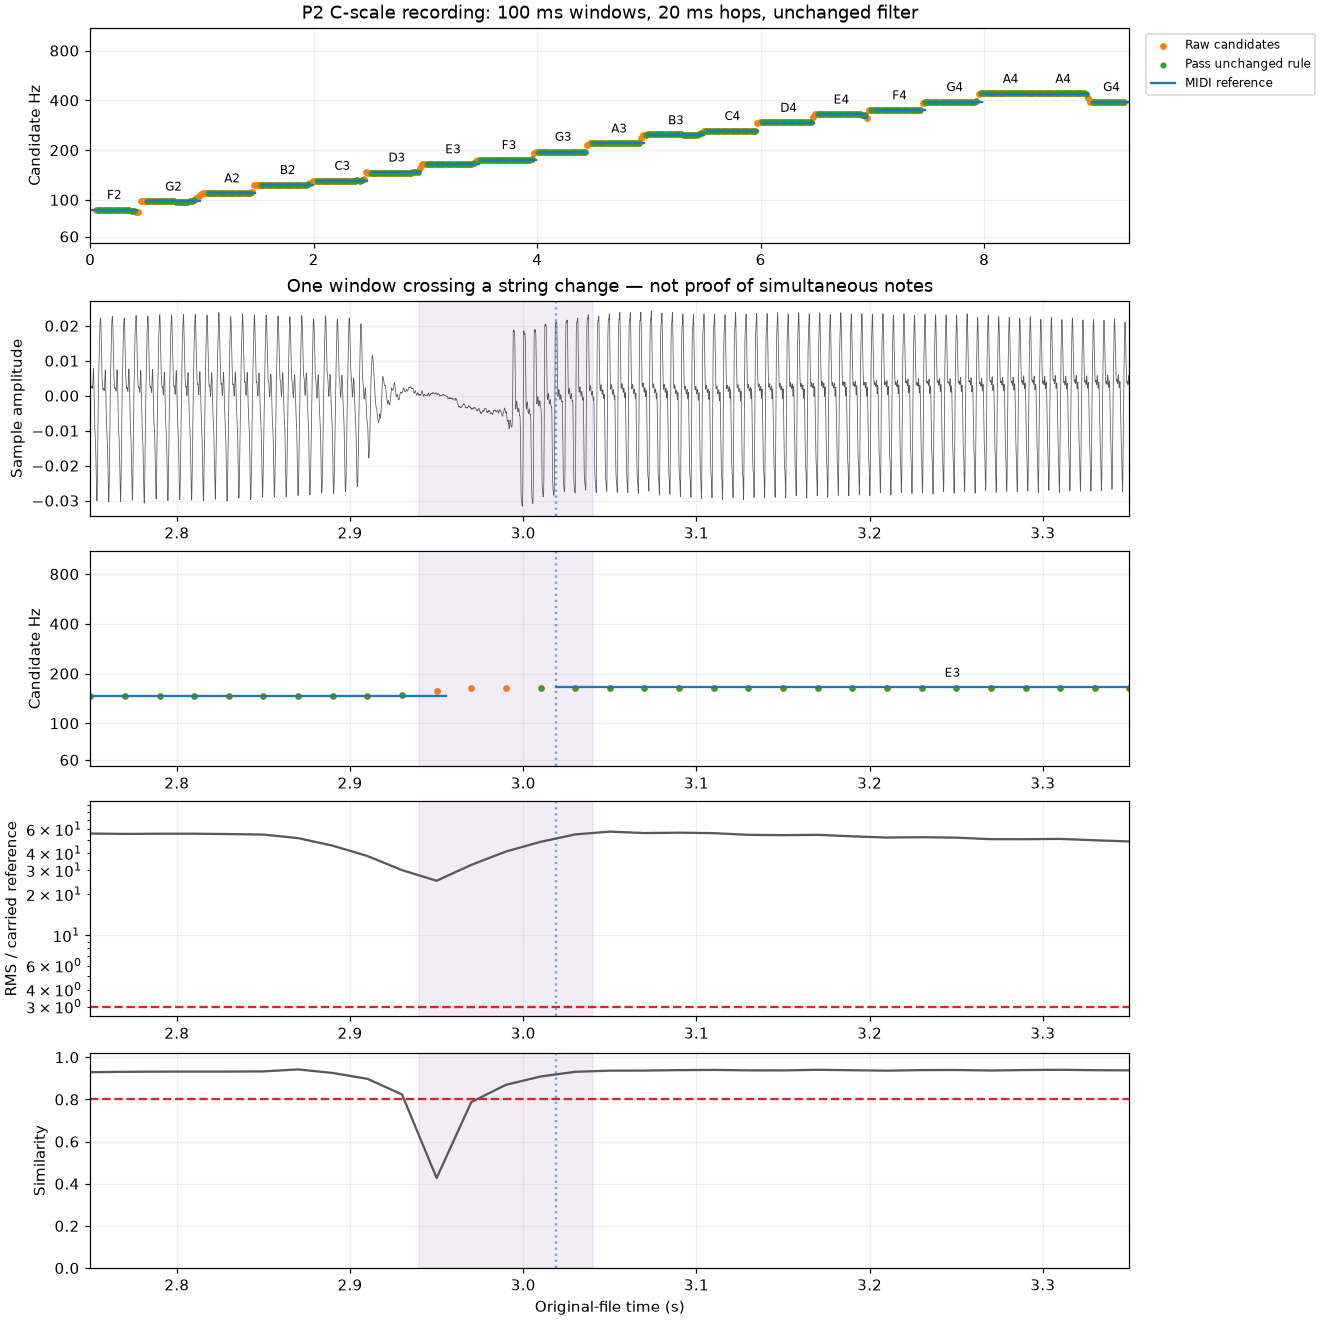

In [5]:
time = np.array([r['midpoint_seconds'] for r in rows])
pitches = np.array([r['candidate_hz'] for r in rows])
accepted_hz = np.array([r['accepted_hz'] for r in rows])
fig, axes = plt.subplots(5, 1, figsize=(12, 12), constrained_layout=True)
for ax in (axes[0], axes[2]):
    ax.scatter(time, pitches, s=12, color='tab:orange', label='Raw candidates')
    ax.scatter(time, accepted_hz, s=9, color='tab:green', label='Pass unchanged rule')
    for i, note in enumerate(labels):
        ax.plot([note['start_seconds'], min(note['end_seconds'], excerpt_seconds)], [note['hz']] * 2,
                color='tab:blue', linewidth=1.5, label='MIDI reference' if i == 0 else None)
        if note['end_seconds'] - note['start_seconds'] >= 0.1:
            midpoint = (note['start_seconds'] + min(note['end_seconds'], excerpt_seconds)) / 2
            if ax is axes[0] or 2.75 <= midpoint <= 3.35:
                ax.annotate(note['name'], (midpoint, note['hz']), xytext=(0, 7), textcoords='offset points', ha='center', fontsize=8)
    ax.set(yscale='log', ylim=(55, 1100), ylabel='Candidate Hz')
    ax.set_yticks([60, 100, 200, 400, 800], labels=['60', '100', '200', '400', '800'])
    ax.minorticks_off()
axes[0].set(title=f'{player} C-scale recording: 100 ms windows, 20 ms hops, unchanged filter', xlim=(0, excerpt_seconds))
axes[0].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
zoom_start, zoom_stop = round(2.75 * rate), round(3.35 * rate)
axes[1].plot(np.arange(zoom_start, zoom_stop) / rate, signal[zoom_start:zoom_stop], linewidth=0.5, color='0.35')
axes[1].set(ylabel='Sample amplitude', title='One window crossing a string change — not proof of simultaneous notes')
axes[3].plot(time, [r['level_ratio'] for r in rows], color='0.35')
axes[3].axhline(minimum_level_ratio, color='tab:red', linestyle='--')
axes[3].set(yscale='log', ylabel='RMS / carried reference')
axes[4].plot(time, [r['similarity'] for r in rows], color='0.35')
axes[4].axhline(minimum_similarity, color='tab:red', linestyle='--')
axes[4].set(ylim=(0, 1.02), ylabel='Similarity', xlabel='Original-file time (s)')
for ax in axes:
    ax.grid(alpha=0.2)
for ax in axes[1:]:
    ax.set_xlim(2.75, 3.35)
    ax.axvspan(2.94, 3.04, color='tab:purple', alpha=0.12)
    for note in labels:
        if 2.75 <= note['start_seconds'] <= 3.35:
            ax.axvline(note['start_seconds'], color='tab:blue', linestyle=':', alpha=0.6)
output_folder = Path('outputs/pitch_tracking')
output_folder.mkdir(parents=True, exist_ok=True)
fig.savefig(output_folder / f'{output_tag}_transitions.png', dpi=150)
plt.show()
print('Midpoint  Hz     Score  Level  Decision / reference spans')
for row in rows:
    if 2.85 <= row['midpoint_seconds'] <= 3.25:
        print(f"{row['midpoint_seconds']:.2f}   {row['candidate_hz']:6.1f}  {row['similarity']:.3f}  {row['level_ratio']:5.1f}  "
              f"{'PASS' if row['accepted'] else row['rejection_reasons']} / {row['intersecting_label_names']}")
path = output_folder / f'{output_tag}_windows.csv'
with path.open('w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
print('Saved:', path)


## Earlier P2 result (2026-11-03; historical comparison)
396 windows; 355 pass. All 119 guarded interior windows pass and agree within
50 cents of their labels. This is conditional interior agreement, not 100%
transcription accuracy: transition regions are deliberately excluded.
42 windows intersect multiple label spans; 21 pass. Passing one pitch in such
a window does NOT mean both notes were detected. All labels remain visible,
including the brief D#4 annotation near 6.93 s and A4 just at the excerpt end.

Read the D3→E3 transition table:
- 2.93 s midpoint: ~147.7 Hz (D3), similarity 0.824, passes.
- 2.95 s: ~155.8 Hz between the two notes, similarity 0.427, rejected.
- 2.99 s: ~164.4 Hz (E3), similarity 0.869; waits for an eligible predecessor.
- 3.01 s: ~164.4 Hz, similarity 0.909, passes.
Every point summarizes 100 ms; these midpoints are not attack timestamps. The
3.01 s point covers [2.96:3.06] s, so it uses samples after the MIDI start at
~3.019 s. An estimate plotted before a marker doesn't mean the code predicts
the future; window placement and annotation misalignment both matter.

We haven't measured simultaneous acoustic overlap or separated two strings.
The plot supports inspecting transitions, not claiming a solved chord detector.
Keep settings fixed. Next group successive passing windows into rough note
events, showing uncertain boundary gaps instead of pretending exact timing.
Repeated same-pitch plucks will later need attack detection. Do not add special
corrections for this scale or silently delete short MIDI labels.


## 5. Group accepted windows into note-evidence runs
Read `group_pitch_windows` in note_events.py: it takes audio measurements only,
has no file/plot/MIDI dependencies, and returns a table. This separates the new
grouping step from the unchanged pitch estimator and acceptance rule.

Map Hz to a note coordinate: `69 + 12 * log2(hz / 440)`.
A4=440 Hz maps to 69; doubling Hz adds 12 (one octave). Round to the nearest
integer to name the nearest equal-tempered note. This is a naming convention,
NOT a confidence score or a lookup in the supplied MIDI annotations. It assumes
A4=440 Hz. The typical measured frequency is retained instead of snapped to it.

Walk through windows in order:
1. Rejected or missing window: finish the current group; never fill the gap.
2. Accepted, same nearest note: append to the current group.
3. Accepted, different note: finish the old group and start another.
Finish the final group at excerpt end. Retain one-window groups as points;
no duration cutoff or merging was added just to make this scale look cleaner.

Timing distinction: event bars run from FIRST to LAST accepted window MIDPOINT.
These are evidence spans, NOT estimated attack/end times. The source samples
behind each run extend half a window beyond those midpoints and can overlap
another run's source samples. That is analysis overlap, not proof of two notes
sounding together. A singleton has one midpoint, not zero physical duration.


In [6]:
from note_events import group_pitch_windows

# Exclude reference-label fields explicitly: grouping must work without MIDI.
audio_rows = [{key: row[key] for key in (
    'start_sample', 'stop_sample_exclusive', 'sample_rate', 'candidate_hz', 'accepted')}
    for row in rows]
events = group_pitch_windows(audio_rows, hop)
assert sum(event['window_count'] for event in events) == sum(row['accepted'] for row in rows)
print(f'{len(events)} evidence runs from {sum(row["accepted"] for row in rows)} accepted windows.')
print('ID  Note   Median Hz  First midpoint  Last midpoint  Windows')
for event in events:
    print(f"{event['event_id']:2d}  {event['note_name']:4s}   {event['median_hz']:8.2f}  "
          f"{event['first_midpoint_seconds']:8.3f} s     {event['last_midpoint_seconds']:8.3f} s   "
          f"{event['window_count']:4d}")
print('Rejected windows remain gaps. These are not confirmed attacks or separate plucks.')


18 evidence runs from 418 accepted windows.
ID  Note   Median Hz  First midpoint  Last midpoint  Windows
 1  F2        86.96     0.070 s        0.390 s     17
 2  G2        97.76     0.510 s        0.930 s     22
 3  A2       109.84     1.050 s        1.430 s     20
 4  B2       123.08     1.530 s        1.950 s     22
 5  C3       130.43     2.030 s        2.430 s     21
 6  D3       146.34     2.510 s        2.930 s     22
 7  E3       164.38     3.010 s        3.430 s     22
 8  F3       174.55     3.490 s        3.950 s     24
 9  G3       195.92     4.010 s        4.430 s     22
10  A3       220.18     4.490 s        4.910 s     22
11  B3       248.70     4.970 s        5.470 s     26
12  C4       262.30     5.510 s        5.950 s     23
13  D4       294.48     6.010 s        6.450 s     23
14  E4       331.03     6.510 s        6.930 s     22
15  F4       350.36     6.990 s        7.430 s     23
16  G4       393.44     7.470 s        7.930 s     24
17  A4       440.37     7.970 s

## 6. Inspect the groups beside the reference, keeping uncertainty visible
Upper panel: green bars summarize accepted estimates; green dots mark the
contributing window midpoints. Gray crosses are rejected raw estimates.
No bar bridges a rejection. A missing bar is NOT proof of acoustic silence.
Lower panel: the original MIDI intervals, used only for visual comparison.
Their boundaries mean something different from our window-midpoint spans.
Repeated same-note groups can be fragmentation rather than separate plucks;
uninterrupted repeated picking can merge. Bends/vibrato can cross note bins.


Saved: outputs/pitch_tracking/P2_scale_C_0-9.3s_note_evidence.csv


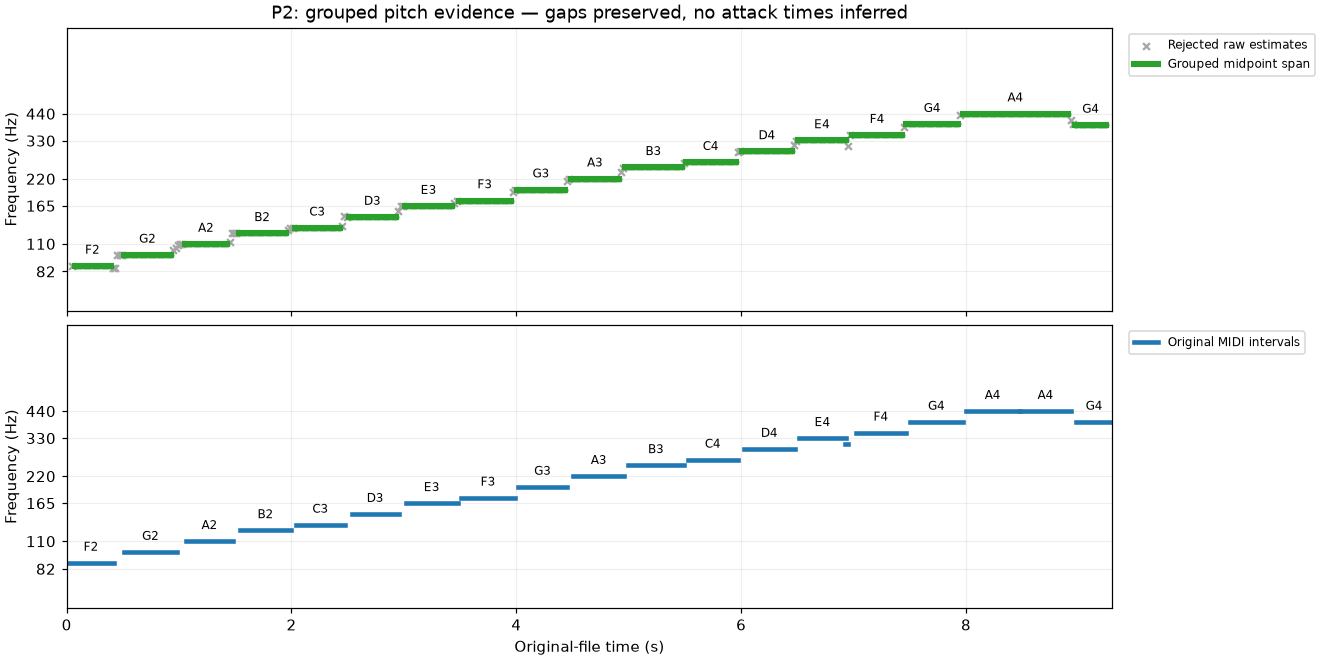

In [7]:
event_fig, event_axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True)
rejected = np.array([not row['accepted'] for row in rows])
event_axes[0].scatter(time[rejected], pitches[rejected], marker='x', s=20,
                      color='0.65', label='Rejected raw estimates')
for index, event in enumerate(events):
    first, last = event['first_midpoint_seconds'], event['last_midpoint_seconds']
    hz = event['median_hz']
    event_axes[0].plot([first, last], [hz, hz], color='tab:green', linewidth=4,
                       label='Grouped midpoint span' if index == 0 else None)
    event_axes[0].scatter([row['midpoint_seconds'] for row in rows[event['first_frame_index']:event['last_frame_index'] + 1]],
                          [hz] * event['window_count'], color='tab:green', s=8)
    event_axes[0].annotate(event['note_name'], ((first + last) / 2, hz),
                          xytext=(0, 8), textcoords='offset points', ha='center', fontsize=8)
for index, note in enumerate(labels):
    first, last = max(0, note['start_seconds']), min(excerpt_seconds, note['end_seconds'])
    event_axes[1].plot([first, last], [note['hz']] * 2, color='tab:blue', linewidth=3,
                       label='Original MIDI intervals' if index == 0 else None)
    if last - first >= 0.1:
        event_axes[1].annotate(note['name'], ((first + last) / 2, note['hz']),
                              xytext=(0, 8), textcoords='offset points', ha='center', fontsize=8)
for ax in event_axes:
    ax.set(yscale='log', ylim=(minimum_frequency * 0.9, maximum_frequency * 1.1),
           ylabel='Frequency (Hz)', xlim=(0, excerpt_seconds))
    ax.set_yticks([82, 110, 165, 220, 330, 440], labels=['82', '110', '165', '220', '330', '440'])
    ax.minorticks_off()
    ax.grid(alpha=0.2)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
event_axes[0].set_title(f'{player}: grouped pitch evidence — gaps preserved, no attack times inferred')
event_axes[1].set_xlabel('Original-file time (s)')
event_fig.savefig(output_folder / f'{output_tag}_note_evidence.png', dpi=150)
plt.show()

# Keep the old per-window CSV unchanged. Export the grouping separately.
event_path = output_folder / f'{output_tag}_note_evidence.csv'
event_fields = ['event_id', 'note_number', 'note_name', 'median_hz', 'window_count',
                'first_frame_index', 'last_frame_index', 'first_midpoint_seconds',
                'last_midpoint_seconds', 'source_start_sample', 'source_stop_sample_exclusive', 'sample_rate']
with event_path.open('w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=event_fields)
    writer.writeheader()
    writer.writerows(events)
print('Saved:', event_path)


## Earlier P2 grouping result and limits (historical comparison)
355 accepted windows form 16 runs, F2 → G2 → A2 → B2 → C3 → D3 → E3 → F3
→ G3 → A3 → B3 → C4 → D4 → E4 → F4 → G4, without using MIDI labels to group.
No accepted window is discarded. For example, D3 has midpoint evidence from
2.51–2.93 s and E3 from 3.01–3.43 s. The gap is visible; it is not called silence.
Their underlying sample spans overlap by 20 ms because each window is 100 ms.

The original MIDI still includes a brief D#4 annotation and A4 at the excerpt
edge; the grouping didn't force a match to the annotation count. A4's final
raw candidate is rejected by the existing filter, so no A4 group is fabricated.
These are provisional note candidates, not a validated tab transcription.
Next inspect one group's member rows, then try a passage with repeated pitches
to see what attack detection must add. Keep uncertainty visible rather than
bridging every gap or tuning durations until these 16 bars match the labels.


## P1 transfer result and the next attack example (2026-11-03)
`player = 'P1'` selects the corresponding scale and P1's old single-note
reference. Set `player = 'P2'` to reproduce the preceding example. Both use
unchanged estimator, acceptance and grouping settings. Outputs include player
and excerpt length so the two examples don't overwrite each other.

| First 8 seconds | P1 | P2 |
|---|---:|---:|
| Analysis windows | 396 | 396 |
| Passing windows | 316 | 355 |
| Evidence groups | 14 | 16 |
| Guarded interior windows passing | 109 / 109 | 119 / 119 |
| Passing interior errors >50 cents | 0 | 0 |

P1's first 0.9 s contains exact digital zeros and its MIDI sequence starts at
A2 around 1.02 s; P2 includes F2 and G2 earlier. Thus the group-count difference
is NOT two missed P1 notes. P1's 14 groups follow A2 through G4 once each; no
extra fragmentation or merging of neighboring pitches appears in this excerpt.
This is a short, slow-scale transfer check, not full transcription accuracy.
The carried background reference remains an assumption across files.

We also inspected through 9.3 s, holding every setting fixed. Both MIDI files
contain two successive A4 labels around 8–9 s:
- P1 labels: 8.007–8.472, 8.502–8.935 s. Groups: 7.97–8.41 and 8.47–8.91 s.
  Windows at 8.43/8.45 are rejected, causing the grouping to split.
- P2 labels: 7.998–8.478, 8.482–8.933 s. ONE group: 7.97–8.91 s, 48 windows.
  The second labeled A4 doesn't change pitch or break acceptance.

To reproduce the next learning example, set player='P2' and
excerpt_seconds=9.3 in the first cell, then run all cells. Inspect 7.8–9.1 s.
Saved 0–9.3 s CSVs/plots already exist for both players. Times above are window
midpoints or supplied annotations, not measured attack times. The annotations
suggest repeated picking; listen/inspect the waveform before asserting exact
physical attacks. Next learn an attack cue for P2's merged A4 pair. Do not tune
pitch thresholds just to force this split. Chord separation is still future work.


## 7. Inspect the repeated A4 waveform before building an attack detector
Current example: player P2, excerpt_seconds=9.3. Inspect 7.8–9.1 s, which
includes both A4 labels and a little surrounding audio. If you change player
to P1 the same plot inspects P1's pair. No detector or event splitting added.

Top: raw waveform over the whole passage. Middle: energy over time, using
10 ms RMS windows advanced by 2 ms, alongside the old 100 ms RMS. At 48 kHz,
10 ms = 480 samples and 2 ms = 96 samples. Smaller windows reveal faster
changes but fluctuate more. These are ONLY visualization measurements; the
pitch estimator still uses 100 ms / 20 ms and all old acceptance settings.
Bottom: close-up around the second A4 label. Dashed lines show supplied MIDI
starts, not detected attacks; don't treat annotation timing as exact audio truth.
No per-clip normalization, offset removal or gain change is applied.


Inspected original samples [374400:436800], 646 full energy windows of 480 samples, hop 96.
Supplied A4 interval: 7.9979–8.4781 s
Supplied A4 interval: 8.4823–8.9333 s
Saved: outputs/pitch_tracking/P2_scale_C_repeated_A4_waveform.png


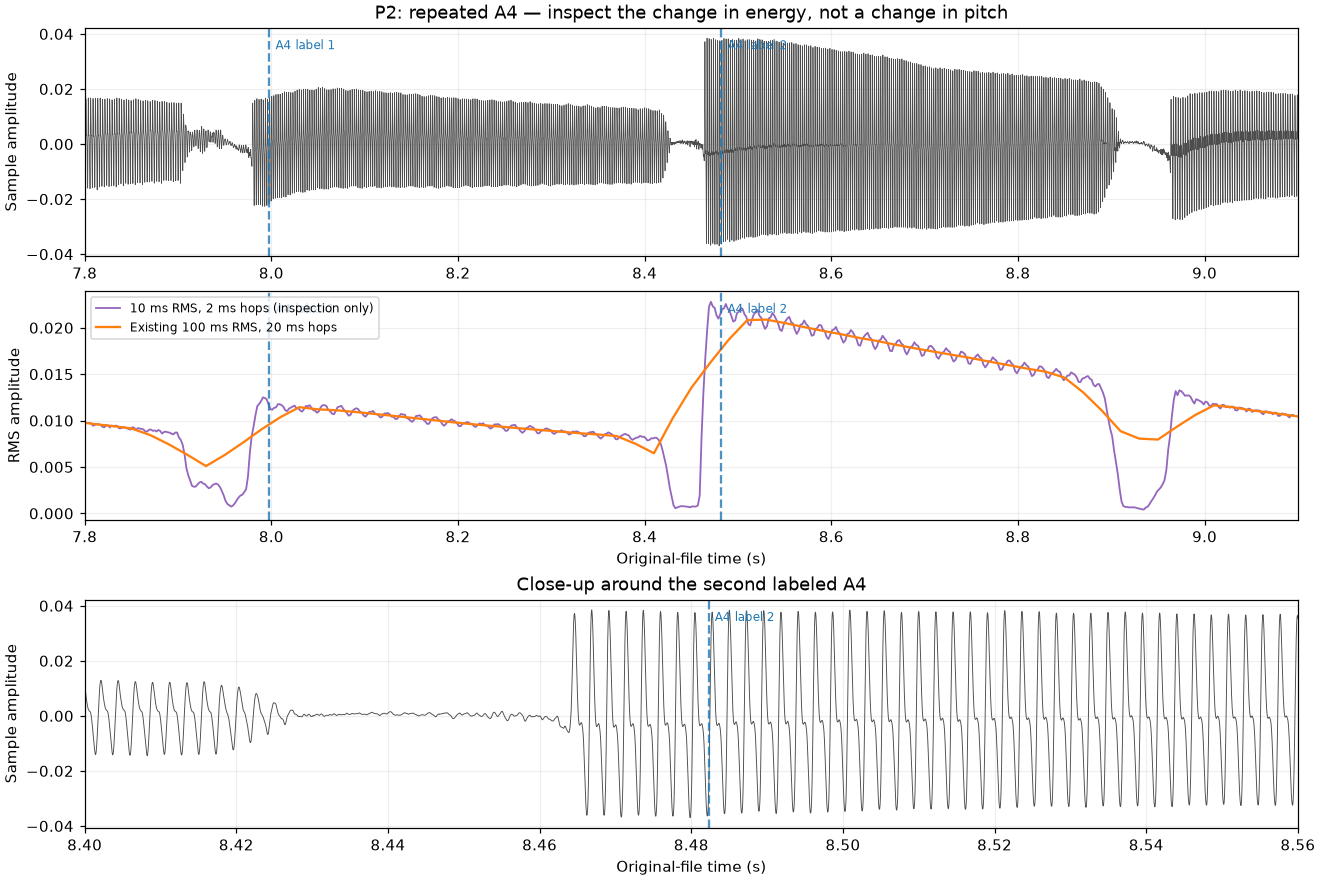

In [8]:
repeat_start_seconds, repeat_stop_seconds = 7.8, 9.1
repeat_start_sample = round(repeat_start_seconds * rate)
repeat_stop_sample = round(repeat_stop_seconds * rate)
if repeat_stop_sample > len(signal):
    raise ValueError('For the repeated-note plot, set excerpt_seconds=9.3 in the first cell and rerun.')
repeat_samples = signal[repeat_start_sample:repeat_stop_sample]
repeat_time = np.arange(repeat_start_sample, repeat_stop_sample) / rate
energy_width = round(0.010 * rate)
energy_hop = round(0.002 * rate)
energy_rows = []
for start in range(repeat_start_sample, repeat_stop_sample - energy_width + 1, energy_hop):
    segment = signal[start:start + energy_width]
    energy_rows.append(dict(start_sample=start, stop_sample_exclusive=start + energy_width,
        midpoint_seconds=(start + energy_width / 2) / rate,
        rms=float(np.sqrt(np.mean(segment ** 2)))))
energy_time = np.array([row['midpoint_seconds'] for row in energy_rows])
energy_rms = np.array([row['rms'] for row in energy_rows])
a4_labels = [note for note in labels if note['midi_note'] == 69
             and note['start_seconds'] < repeat_stop_seconds and note['end_seconds'] > repeat_start_seconds]
repeat_fig, repeat_axes = plt.subplots(3, 1, figsize=(12, 8), constrained_layout=True)
repeat_axes[0].plot(repeat_time, repeat_samples, color='0.3', linewidth=0.5)
repeat_axes[0].set(title=f'{player}: repeated A4 — inspect the change in energy, not a change in pitch',
                   ylabel='Sample amplitude', xlim=(repeat_start_seconds, repeat_stop_seconds))
repeat_axes[1].plot(energy_time, energy_rms, color='tab:purple', linewidth=1.2,
                   label='10 ms RMS, 2 ms hops (inspection only)')
repeat_axes[1].plot(time, [row['rms'] for row in rows], color='tab:orange', linewidth=1.5,
                   label='Existing 100 ms RMS, 20 ms hops')
repeat_axes[1].set(ylabel='RMS amplitude', xlabel='Original-file time (s)',
                   xlim=(repeat_start_seconds, repeat_stop_seconds))
repeat_axes[1].legend(fontsize=8, loc='upper left')
close_start, close_stop = round(8.40 * rate), round(8.56 * rate)
repeat_axes[2].plot(np.arange(close_start, close_stop) / rate, signal[close_start:close_stop],
                   color='0.3', linewidth=0.6)
repeat_axes[2].set(xlim=(8.40, 8.56), ylabel='Sample amplitude', xlabel='Original-file time (s)',
                   title='Close-up around the second labeled A4')
for ax in repeat_axes:
    ax.grid(alpha=0.2)
    for index, note in enumerate(a4_labels):
        if ax.get_xlim()[0] <= note['start_seconds'] <= ax.get_xlim()[1]:
            ax.axvline(note['start_seconds'], color='tab:blue', linestyle='--', alpha=0.8)
            ax.annotate(f"A4 label {index + 1}", (note['start_seconds'], 0.97),
                        xycoords=('data', 'axes fraction'), xytext=(4, -3),
                        textcoords='offset points', va='top', fontsize=8, color='tab:blue')
repeat_figure_path = output_folder / f'{player}_scale_C_repeated_A4_waveform.png'
repeat_fig.savefig(repeat_figure_path, dpi=150)
plt.show()
energy_path = output_folder / f'{player}_scale_C_repeated_A4_10ms_rms.csv'
with energy_path.open('w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(energy_rows[0]))
    writer.writeheader()
    writer.writerows(energy_rows)
print(f'Inspected original samples [{repeat_start_sample}:{repeat_stop_sample}], '
      f'{len(energy_rows)} full energy windows of {energy_width} samples, hop {energy_hop}.')
for note in a4_labels:
    print(f"Supplied A4 interval: {note['start_seconds']:.4f}–{note['end_seconds']:.4f} s")
print('Saved:', repeat_figure_path)


For P2, the waveform/short RMS show a dip around 8.44 s followed by renewed
energy around 8.45–8.48 s, while the pitch remains near A4. The 100 ms RMS
mixes samples across this short dip and smooths it substantially. This is a
useful candidate attack cue: a change in energy can mark another pluck even
when the frequency doesn't change. We haven't measured an exact attack time.
The MIDI start ~8.482 s is a reference marker, not proof the attack began there.
Do not set a threshold from this single dip. Next compare the shape with P1
and another transition before choosing a simple, explained attack rule.
